# Syrus 01 — case evidence review

Review of the Syrus case files before any language model is wired to them.

**Question.** Do the deterministic case records and findings ledger state what the frozen detector evidence supports — in particular for the featured alert (2020-05-29 21:20), whose margin is small and whose raw score at the alert bin is tiny?

**Inputs (read-only).** `docs/syrus/cases/*.json`, built by `python -m scripts.build_syrus_cases` from the frozen reports `docs/xai_report.json`, `docs/xai_verification_report.json`, `docs/detector_benchmark.json`, `docs/proof_manifest.json` and the configs it names. The case files carry the content hash of every source they read.

**Outputs.** Tables and one figure inline; the figure is also saved to `outputs/syrus_01/` (gitignored). Nothing under `docs/` is written, no frozen notebook is executed, and no detector value is recomputed: every number below is a frozen value or arithmetic on frozen values.

**Reproduce.** From the repository root: `python -m scripts.build_syrus_cases --check`, then run this notebook top to bottom.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "backend").exists() and (ROOT.parent / "backend").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from backend.syrus_app.records import Sources, check_case
from scripts.build_syrus_cases import OUT, build_files

OUT_DIR = ROOT / "outputs" / "syrus_01"
OUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 200)

fresh = build_files(Sources(ROOT))
on_disk = {p.name: json.loads(p.read_text("utf-8")) for p in OUT.glob("*.json")}
assert on_disk == fresh, "case files are stale: run python -m scripts.build_syrus_cases"
for name, case in on_disk.items():
    if name != "manifest.json":
        check_case(case)

manifest = on_disk["manifest.json"]
retro = [on_disk[c["files"]["retro"]["path"]] for c in manifest["cases"]]
R = {c["case_id"]: {r["id"]: r for r in c["records"]} for c in retro}
label = {c["case_id"]: f"{c['alert_time'][:16]} ({c['case_id']})" for c in retro}
featured = next(c["case_id"] for c in retro if c["role"] == "featured")
print("manifest", manifest["sha256"][:12], "| cases in alert-time order:", [label[c["case_id"]] for c in retro])

manifest 26fab01b7270 | cases in alert-time order: ['2020-04-18 00:40 (c-r6tq)', '2020-05-29 21:20 (c-h3vz)', '2020-06-05 10:10 (c-w8nk)', '2020-07-15 08:45 (c-b5xm)']


## 1. Findings ledger across the four cases

One row per rule. `fires` says whether the rule's condition holds for that case; the text is built only from the display strings of the rule's input records.

In [2]:
ledger = pd.DataFrame(
    [{"finding": f["id"], "case": label[c["case_id"]], "fires": f["fires"], "visibility": f["visibility"]} for c in retro for f in c["findings"]]
).pivot(index="finding", columns="case", values="fires")
ledger = ledger.loc[[f["id"] for f in retro[0]["findings"]]]
ledger

case,2020-04-18 00:40 (c-r6tq),2020-05-29 21:20 (c-h3vz),2020-06-05 10:10 (c-w8nk),2020-07-15 08:45 (c-b5xm)
finding,,,,
F-MARGIN,True,True,True,True
F-CARRYOVER,False,True,False,True
F-EMERGE,True,True,True,True
F-CF-SPEC,False,True,False,True
F-CF-PERSIST,False,False,False,True
F-HYP-TIE,True,True,True,True
F-SCALE,True,True,True,True
F-GAP,True,False,False,False
F-IDENT,True,True,True,True


In [3]:
for f in next(c for c in retro if c["case_id"] == featured)["findings"]:
    print(f"{f['id']:13} [{f['visibility']}] {f['text']}\n")

F-MARGIN      [both] The smoothed score (58,989) exceeded the threshold (52,942) by +11.4%, a marginal alert.

F-CARRYOVER   [both] The alert bin's own raw score was 35.8 (0.07% of the threshold); the smoothed score above the threshold was carried from earlier bins by EWMA memory. The smoothed score one bin earlier, at 21:15, follows from the EWMA update as 73,727.

F-EMERGE      [both] Smoothed evidence rose abruptly between 21:05 and 21:10: dv_pressure went from percentile 35.08 to 100; motor_current went from percentile 35.36 to 99.78. This shows when detector evidence appeared, not when a fault began.

F-CF-SPEC     [both] Removing the model-space evidence of any one of dv_pressure, tp2 or motor_current clears this alert (repaired smoothed scores 7,472, 51,473 and 48,374 against the 52,942 threshold), so the detector's decision is not specific to dv_pressure. This tests detector dependence, not a physical repair.

F-CF-PERSIST  [both] Every repair that clears the alert also brings 

## 2. Carryover: how much of the featured alert is smoothing memory

The smoothed score follows $s_t = \alpha x_t + (1-\alpha) s_{t-1}$ with $\alpha = 0.2$, restarting at the raw value after a gap over 10 minutes. The frozen reports give $s_t$ and $x_t$ only at the alert bin, so the previous smoothed value is exact arithmetic when the previous bin is within the reset gap: $s_{t-1} = (s_t - \alpha x_t)/(1-\alpha)$.

In [4]:
rows = []
for c in retro:
    r = R[c["case_id"]]
    a = r["detector.ewma"]["value"]["alpha"]
    s, x, thr = (r[k]["value"] for k in ("alert.smoothed", "alert.raw", "alert.threshold"))
    prev = r["alert.prev_smoothed"]["value"]
    rows.append({"case": label[c["case_id"]], "raw x_t": round(x, 1), "x_t / threshold": round(x / thr, 4),
                 "smoothed s_t": round(s), "margin": f"{s / thr - 1:+.1%}",
                 "previous bin": prev["time"][11:16], "s_(t-1)": round(prev["score"]), "s_(t-1) >= threshold": prev["score"] >= thr,
                 "share of s_t carried from s_(t-1)": f"{(1 - a) * prev['score'] / s:.2%}"})
pd.DataFrame(rows).set_index("case")

,raw x_t,x_t / threshold,smoothed s_t,margin,previous bin,s_(t-1),s_(t-1) >= threshold,share of s_t carried from s_(t-1)
case,,,,,,,,
2020-04-18 00:40 (c-r6tq),197231.2,3.7254,180453,+240.9%,00:35,176258,True,78.14%
2020-05-29 21:20 (c-h3vz),35.8,0.0007,58989,+11.4%,21:15,73727,True,99.99%
2020-06-05 10:10 (c-w8nk),154559.4,2.9194,96205,+81.7%,10:05,81616,True,67.87%
2020-07-15 08:45 (c-b5xm),22696.3,0.4287,63497,+19.9%,08:40,73697,True,92.85%


For the featured case the alert bin itself contributes $0.2 \times 35.8 \approx 7$ of the 58,989 smoothed score; the rest is carried from 21:15, whose smoothed score works out to about 73,727, also above the threshold.

**What persistence implies.** The alert needs at least 3 of the last 4 smoothed scores at or above the threshold, and 21:20 is the first alert bin. 21:15 and 21:20 are hits. If both 21:05 and 21:10 were also hits, 21:15 would already have had 3 hits in its window and alerted, so **exactly one of 21:05 or 21:10 is a hit**. The frozen artifacts do not export those smoothed scores, so which one is not pinned here; the percentile jump in section 4 points to 21:10, but percentiles of single groups do not bound the total score.

**Single-bin bound.** From a near-zero state one bin with raw score $x$ yields smoothed values $0.2x, 0.16x, 0.128x$ over three bins; all three reach the threshold $T$ only if $x \ge T/0.128 \approx 7.8T$. Right after a reset the sequence is $x, 0.8x, 0.64x$, which needs only $x \ge T/0.64 \approx 1.56T$. So one large bin can produce an alert on its own, and more easily just after a data gap.

In [5]:
T = R[featured]["alert.threshold"]["value"]
for start, seq in (("near-zero state", [0.2, 0.16, 0.128]), ("after a reset", [1.0, 0.8, 0.64])):
    print(f"{start:16}: three consecutive hits need raw >= {T / seq[-1]:,.0f} ({1 / seq[-1]:.4g} x threshold)")

near-zero state : three consecutive hits need raw >= 413,608 (7.812 x threshold)
after a reset   : three consecutive hits need raw >= 82,722 (1.562 x threshold)


## 3. Calibration ranks

Percentiles are mid-ranks against the 1,796 calibration bins. For a continuous contribution with no exact ties, `percentile × 1,796` is the count of calibration bins below the value, so the count above is exact. The check below confirms every displayed percentile is an integer multiple of 1/1,796.

In [6]:
rows = []
for c in retro:
    r = R[c["case_id"]]
    n = r["detector.calibration_bins"]["value"]
    for g in r["temporal.window"]["value"]["groups"]:
        p = r[f"contrib.{g}"]["value"]["percentile"]
        rows.append({"case": label[c["case_id"]], "group": g, "share": r[f"contrib.{g}"]["display"]["share"], "percentile": p,
                     "p × n": round(p * n, 6), "integer": abs(p * n - round(p * n)) < 1e-6, "bins higher": r[f"calrank.{g}"]["display"]})
pd.DataFrame(rows).set_index(["case", "group"])

share  percentile   p × n  integer  \
case                      group                                               
2020-04-18 00:40 (c-r6tq) tp2            94.0%    1.000000  1796.0     True   
                          dv_pressure     6.0%    0.907016  1629.0     True   
2020-05-29 21:20 (c-h3vz) dv_pressure    77.6%    0.995546  1788.0     True   
                          tp2            12.6%    0.999443  1795.0     True   
                          motor_current   9.8%    0.990535  1779.0     True   
2020-06-05 10:10 (c-w8nk) tp2            86.1%    1.000000  1796.0     True   
                          dv_pressure    13.0%    0.920379  1653.0     True   
2020-07-15 08:45 (c-b5xm) dv_pressure    74.5%    0.995546  1788.0     True   
                          tp2            13.8%    1.000000  1796.0     True   
                          motor_current  11.7%    0.995546  1788.0     True   

                                          bins higher  
case                      group                        
2020-04-18 00:40 (c-r6tq) tp2              0 of 1,796  
                          dv_pressure    167 of 1,796  
2020-05-29 21:20 (c-h3vz) dv_pressure      8 of 1,796  
                          tp2              1 of 1,796  
                          motor_current   17 of 1,796  
2020-06-05 10:10 (c-w8nk) tp2              0 of 1,796  
                          dv_pressure    143 of 1,796  
2020-07-15 08:45 (c-b5xm) dv_pressure      8 of 1,796  
                          tp2              0 of 1,796  
                          motor_current    8 of 1,796

## 4. Past-only temporal window (smoothed evidence)

Calibration percentile of each displayed group's **smoothed** contribution over the 12 bins ending at the alert. This shows when detector evidence appeared, not when a fault began, and it is not the raw signal.

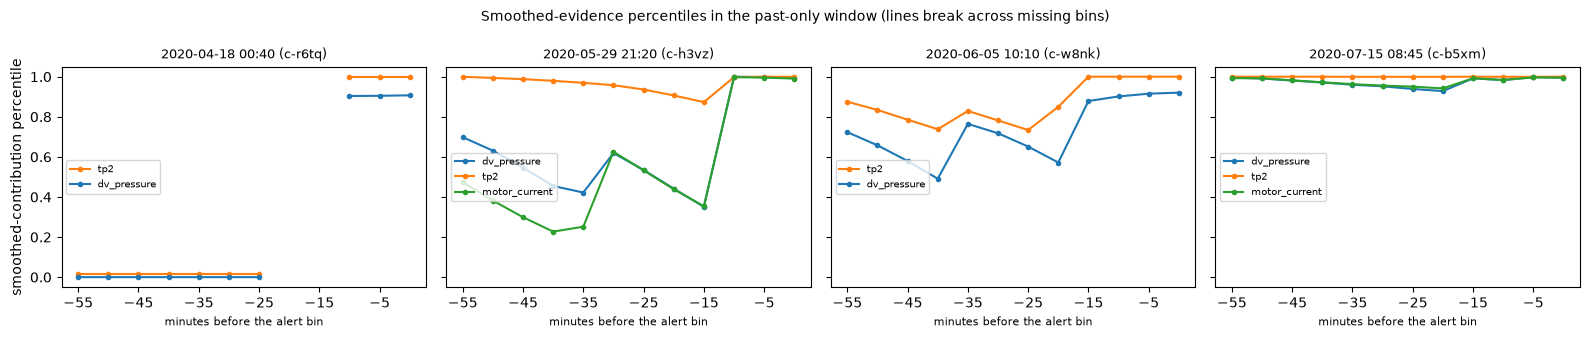

In [7]:
from backend.syrus_app.records import minutes

colors = {"dv_pressure": "C0", "tp2": "C1", "motor_current": "C2"}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for ax, c in zip(axes, retro):
    r = R[c["case_id"]]
    tids = [i for i in r if i.startswith("temporal.") and i != "temporal.window"]
    for g in r["temporal.window"]["value"]["groups"]:
        xs, ys, prev = [], [], None
        for i in tids:
            t = r[i]["value"]["time"]
            if prev and minutes(prev, t) > 5:  # break the line across missing bins
                xs.append(float("nan")); ys.append(float("nan"))
            xs.append(-minutes(t, c["alert_time"])); ys.append(r[i]["value"]["percentiles"][g])
            prev = t
        ax.plot(xs, ys, marker="o", ms=3, color=colors[g], label=g)
    ax.set_title(label[c["case_id"]], fontsize=9)
    ax.set_xlabel("minutes before the alert bin", fontsize=8)
    ax.set_xticks(range(-55, 1, 10))
    ax.legend(fontsize=7, loc="center left")
axes[0].set_ylabel("smoothed-contribution percentile")
fig.suptitle("Smoothed-evidence percentiles in the past-only window (lines break across missing bins)", fontsize=10)
fig.tight_layout()
fig.savefig(OUT_DIR / "temporal_percentiles.png", dpi=120)
plt.show()

In [8]:
pd.DataFrame([{"case": label[c["case_id"]], **next(f for f in c["findings"] if f["id"] == "F-EMERGE")["output"]} for c in retro]).set_index("case")

,pattern,from,at,groups
case,,,,
2020-04-18 00:40 (c-r6tq),abrupt,2020-04-18 00:15:00,2020-04-18 00:30:00,[tp2]
2020-05-29 21:20 (c-h3vz),abrupt,2020-05-29 21:05:00,2020-05-29 21:10:00,"[dv_pressure, motor_current]"
2020-06-05 10:10 (c-w8nk),gradual,2020-06-05 09:50:00,2020-06-05 09:55:00,[dv_pressure]
2020-07-15 08:45 (c-b5xm),elevated_at_start,NaN,2020-07-15 07:50:00,[dv_pressure]


## 5. Counterfactual repairs (detector dependence)

Each row replaces one group's model-space coordinates with the PCA reconstruction and reruns the unchanged EWMA, threshold and persistence rule. In the two marginal cases three different single-group repairs each clear the alert, so the repair is not specific to the dominant group. In the 2020-07-15 case the `tp2` repair leaves the smoothed score above the threshold at the alert bin, yet the alert clears because fewer than 3 of the last 4 bins stay above it.

In [9]:
rows = []
for c in retro:
    r = R[c["case_id"]]
    thr = r["alert.threshold"]["value"]
    for i in (k for k in r if k.startswith("cf.")):
        v = r[i]["value"]
        rows.append({"case": label[c["case_id"]], "group": v["group"], "repaired smoothed": round(v["repaired_smoothed"]),
                     "above threshold": v["repaired_smoothed"] >= thr, "alert cleared": v["cleared"]})
pd.DataFrame(rows).set_index(["case", "group"])

repaired smoothed  \
case                      group                                       
2020-04-18 00:40 (c-r6tq) tp2                                 10874   
                          dv_pressure                        169570   
                          motor_current                      180436   
                          h1                                 180449   
                          pressure_relationships             180451   
2020-05-29 21:20 (c-h3vz) dv_pressure                          7472   
                          tp2                                 51473   
                          motor_current                       48374   
                          oil_temperature                     58988   
                          h1                                  58989   
2020-06-05 10:10 (c-w8nk) tp2                                 13460   
                          dv_pressure                         82955   
                          motor_current                       94643   
                          h1                                  96202   
                          pressure_relationships              96204   
2020-07-15 08:45 (c-b5xm) dv_pressure                          9929   
                          tp2                                 54996   
                          motor_current                       49993   
                          oil_temperature                     63495   
                          h1                                  63496   

                                                  above threshold  \
case                      group                                     
2020-04-18 00:40 (c-r6tq) tp2                               False   
                          dv_pressure                        True   
                          motor_current                      True   
                          h1                                 True   
                          pressure_relationships             True   
2020-05-29 21:20 (c-h3vz) dv_pressure                       False   
                          tp2                               False   
                          motor_current                     False   
                          oil_temperature                    True   
                          h1                                 True   
2020-06-05 10:10 (c-w8nk) tp2                               False   
                          dv_pressure                        True   
                          motor_current                      True   
                          h1                                 True   
                          pressure_relationships             True   
2020-07-15 08:45 (c-b5xm) dv_pressure                       False   
                          tp2                                True   
                          motor_current                     False   
                          oil_temperature                    True   
                          h1                                 True   

                                                  alert cleared  
case                      group                                  
2020-04-18 00:40 (c-r6tq) tp2                              True  
                          dv_pressure                     False  
                          motor_current                   False  
                          h1                              False  
                          pressure_relationships          False  
2020-05-29 21:20 (c-h3vz) dv_pressure                      True  
                          tp2                              True  
                          motor_current                    True  
                          oil_temperature                 False  
                          h1                              False  
2020-06-05 10:10 (c-w8nk) tp2                              True  
                          dv_pressure                     False  
                          motor_current     

## 6. Scale: narrow training ranges

Measured five-minute feature values at the alert bin (the frozen `physical_context`), with training-period quartiles. Units come from the dataset description, which is not loaded yet, so none are shown. Distances in IQR units are listed for review only; the product does not use them as headline numbers.

In [10]:
xai = json.loads((ROOT / "docs" / "xai_report.json").read_text("utf-8"))
dist = {(m["incident_id"], m["feature"]): m["iqr_distance"] for m in xai["diagnostics"]["physical_context"]}
rows = []
for c in retro:
    r = R[c["case_id"]]
    for i in (k for k in r if k.startswith("measured.")):
        v = r[i]["value"]
        pos = "below" if v["value"] < v["q1"] else "above" if v["value"] > v["q3"] else "inside"
        rows.append({"case": label[c["case_id"]], "feature": v["feature"], "value": v["value"], "train q1": v["q1"], "train q3": v["q3"],
                     "IQR": v["q3"] - v["q1"], "position": pos, "IQR distance (review only)": round(dist[(c["source"]["incident_id"], v["feature"])], 1)})
pd.DataFrame(rows).set_index(["case", "feature"])

value  train q1  train q3  \
case                      feature                                            
2020-04-18 00:40 (c-r6tq) tp2__mean           8.815355 -0.012129 -0.008533   
                          tp2__min            7.616000 -0.016000 -0.012000   
                          tp2__max            9.096000 -0.010000 -0.006000   
2020-05-29 21:20 (c-h3vz) dv_pressure__std    0.000860  0.000792  0.001008   
                          motor_current__min  0.042500  0.035000  0.037500   
                          dv_pressure__last  -0.020000 -0.020000 -0.016000   
2020-06-05 10:10 (c-w8nk) tp2__mean           8.030774 -0.012129 -0.008533   
                          tp2__min            6.318000 -0.016000 -0.012000   
                          tp2__max            8.446000 -0.010000 -0.006000   
2020-07-15 08:45 (c-b5xm) dv_pressure__std    0.001126  0.000792  0.001008   
                          motor_current__min  3.610000  0.035000  0.037500   
                          tp2__mean           4.702600 -0.012129 -0.008533   

                                                   IQR position  \
case                      feature                                 
2020-04-18 00:40 (c-r6tq) tp2__mean           0.003596    above   
                          tp2__min            0.004000    above   
                          tp2__max            0.004000    above   
2020-05-29 21:20 (c-h3vz) dv_pressure__std    0.000216   inside   
                          motor_current__min  0.002500    above   
                          dv_pressure__last   0.004000   inside   
2020-06-05 10:10 (c-w8nk) tp2__mean           0.003596    above   
                          tp2__min            0.004000    above   
                          tp2__max            0.004000    above   
2020-07-15 08:45 (c-b5xm) dv_pressure__std    0.000216    above   
                          motor_current__min  0.002500    above   
                          tp2__mean           0.003596    above   

                                              IQR distance (review only)  
case                      feature                                         
2020-04-18 00:40 (c-r6tq) tp2__mean                               2454.6  
                          tp2__min                                1907.5  
                          tp2__max                                2276.0  
2020-05-29 21:20 (c-h3vz) dv_pressure__std                          -0.3  
                          motor_current__min                         3.0  
                          dv_pressure__last                         -0.5  
2020-06-05 10:10 (c-w8nk) tp2__mean                               2236.4  
                          tp2__min                                1583.0  
                          tp2__max                                2113.5  
2020-07-15 08:45 (c-b5xm) dv_pressure__std                           0.9  
                          motor_current__min                      1430.0  
                          tp2__mean                               1310.8

## 7. Candidate explanations and discriminators

Candidates are unranked. `untestable_here` means every listed observation that would separate the candidate from another candidate in play is absent from this asset's data; `not_discriminated` means separating observations exist only in raw MetroPT-3 telemetry, which the frozen evidence does not include.

In [11]:
r = R[featured]
c = next(x for x in retro if x["case_id"] == featured)
display(pd.DataFrame([{"candidate": r[i]["display"]["label"], "status": r[i]["display"]["status"], "against": ", ".join(r[i]["value"]["against"]),
                       "matched groups": ", ".join(r[i]["value"]["matched_groups"]) or "any alert"} for i in r if i.startswith("hyp.")]).set_index("candidate"))
pd.DataFrame([{"discriminator": d["id"], "availability": d["availability"], "pairs": len(d["separates"]), "question (en)": d["question"]["en"]}
              for d in c["discriminators"]]).set_index("discriminator")

,status,against,matched groups
candidate,,,
Air leakage,untestable here,downstream_demand,"dv_pressure, tp2"
Higher downstream air demand,untestable here,air_leakage,"dv_pressure, tp2"
Pressure-regulation behaviour,not discriminated,,dv_pressure
Pressure-sensor inconsistency,not discriminated,,"dv_pressure, tp2"
Compressor performance change,not discriminated,,"tp2, motor_current"
Benign operating transient,not discriminated,,any alert
Detector artifact,not discriminated,,any alert


,availability,pairs,question (en)
discriminator,,,
q_demand_record,absent,1,"Do you have any independent record of downstream air use for this period, such as a flow meter or a consumer-demand log?"
q_cycle_pattern,raw_data_only,3,Do you know whether the compressor's load/unload cycling changed in the hours before this alert?
q_sensor_agreement,raw_data_only,4,"Were the related pressure sensors (TP2, TP3, reservoirs) checked against each other or recalibrated around this time?"
q_load_response,raw_data_only,2,Is there any record of how quickly the compressor built pressure while loaded around this time?
q_persistence,raw_data_only,3,Do you have any information on whether this behaviour lasted many cycles or appeared only briefly?
q_physical_size,raw_data_only,6,"Do you know how large the change in the signal was, in physical units, when the evidence appeared, compared with its normal variation?"


## 8. Reading

- **Featured alert (2020-05-29 21:20).** The smoothed score is 11.4% over the threshold, while the alert bin's own raw score is 35.8, about 0.07% of the threshold. The alert is carried by smoothing memory from evidence that appeared between 21:05 and 21:10, when `dv_pressure` and `motor_current` smoothed-contribution percentiles jumped from about 35 to above 99. At the alert bin, the measured `dv_pressure__std` lies inside its training interquartile range. Removing the model-space evidence of `dv_pressure`, `tp2` or `motor_current` each clears the alert, so it is not specific to `dv_pressure`.
- **2020-07-15 08:45.** Also marginal (+19.9%) and also carried (raw score 43% of the threshold), but its evidence was already near the top of the calibration range at the start of the window, so nothing emerged within it. Its `tp2` repair clears the alert through the persistence rule while the smoothed score stays above the threshold.
- **2020-04-18 00:40 and 2020-06-05 10:10.** Strong alerts whose own raw scores exceed the threshold. Only the `tp2` repair clears them, and the measured `tp2` features sit far above their training interquartile range. The first follows a 15-minute data gap that restarts smoothing and persistence.
- **Limits.** The raw-score series, raw telemetry and units are not loaded, so the size of the 21:10 change in physical units, and which of 21:05 or 21:10 was a hit, cannot be established here. Every candidate explanation stays open; air leakage and downstream demand cannot be separated with this asset's data at all. These are detector-evidence statements, not diagnoses.